<a href="https://colab.research.google.com/github/furalmiqbadi/PCVK26_01_AbdulGhofurAlmiqbadi/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# D. TUGAS PRAKTIKUM

## Persiapan

In [53]:
# library
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
import scipy.ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

In [54]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [55]:
path = "/content/drive/MyDrive/3-Tugas/PCVK"

## 3. Buat Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV)

In [56]:
filename = path + '/gradient.jpg'
img = cv.imread(filename, 0)  # baca sebagai grayscale
thresh = 200  # nilai Threshold yang ditentukan
max = 255

# binaru, piksel > thresh = max , piksel ≤ thresh = 0
binary = np.zeros_like(img)
binary[img > thresh] = max
binary[img <= thresh] = 0

# binary inv, piksel > thresh = 0, piksel ≤ thresh = max
binary_inv = np.zeros_like(img)
binary_inv[img > thresh] = 0
binary_inv[img <= thresh] = max

# trunc, piksel > thresh = thresh, piksel ≤ thresh = tetap
trunc = img.copy()
trunc[img > thresh] = thresh

# tozero, piksel > thresh = tetap, piksel ≤ thresh = 0
tozero = np.zeros_like(img)
tozero[img > thresh] = img[img > thresh]

# tozero inv, piksel > thresh = 0, piksel ≤ thresh = tetap
tozero_inv = img.copy()
tozero_inv[img > thresh] = 0

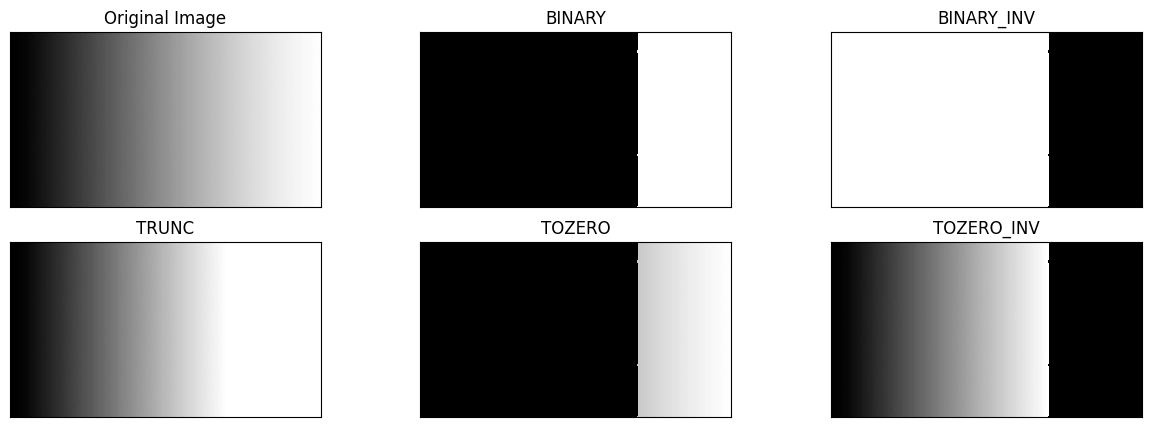

In [57]:
titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i+1), plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

## 4. Buat program Addaptive Threshold

In [58]:
filename = path + '/sudoku-original.jpg'
img = cv.imread(filename)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# ketentuan
thresh_global = 127
window_size = 11
C = 2
sigma = 2

# global thresholding manual, T = 127
global_thresh = np.zeros_like(gray)
global_thresh[gray > thresh_global] = 255
global_thresh[gray <= thresh_global] = 0

# adaptive mean thresholding manual
adaptive_mean = np.zeros_like(gray)
pad = window_size // 2

gray_padded = cv.copyMakeBorder(gray, pad, pad, pad, pad, cv.BORDER_REPLICATE)

for i in range(gray.shape[0]):
    for j in range(gray.shape[1]):
        window = gray_padded[i:i+window_size, j:j+window_size]
        local_mean = np.mean(window) - C
        if gray[i, j] > local_mean:
            adaptive_mean[i, j] = 255
        else:
            adaptive_mean[i, j] = 0
# adaptive gaussian thresholding manual
gaussian_kernel = cv.getGaussianKernel(window_size, sigma)
gaussian_kernel_2d = gaussian_kernel @ gaussian_kernel.T

# normalisasi
gaussian_kernel_2d = gaussian_kernel_2d / np.sum(gaussian_kernel_2d)
adaptive_gaussian = np.zeros_like(gray)

for i in range(gray.shape[0]):
    for j in range(gray.shape[1]):
        window = gray_padded[i:i+window_size, j:j+window_size].astype(np.float64)
        weighted_mean = np.sum(window * gaussian_kernel_2d) - C
        if gray[i, j] > weighted_mean:
            adaptive_gaussian[i, j] = 255
        else:
            adaptive_gaussian[i, j] = 0

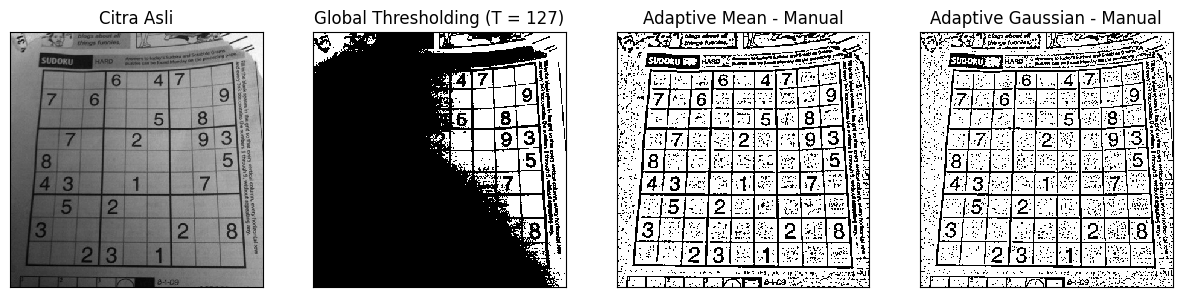

In [59]:
titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
images = [gray, global_thresh, adaptive_mean, adaptive_gaussian]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(1, 4, i+1), plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

## 5. A. Buat Otsu Thresholding tanpa menggunakan Library. B. Kemudian coba dengan image KTP

In [60]:
# otsu thresholding manual
def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

/tmp/ipykernel_2472/685701429.py:16: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)


114


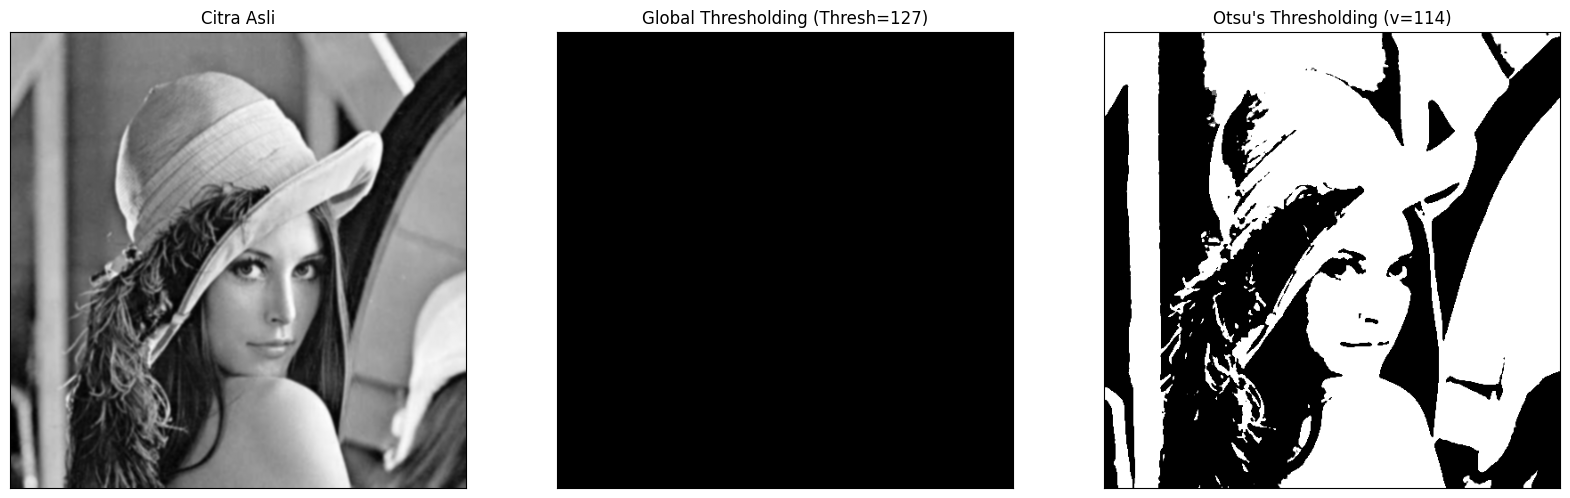

In [61]:
filename = path + '/lena_gs_lc2.jpg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v=") + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 0, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh=' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i+1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

/tmp/ipykernel_2472/685701429.py:15: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)


166


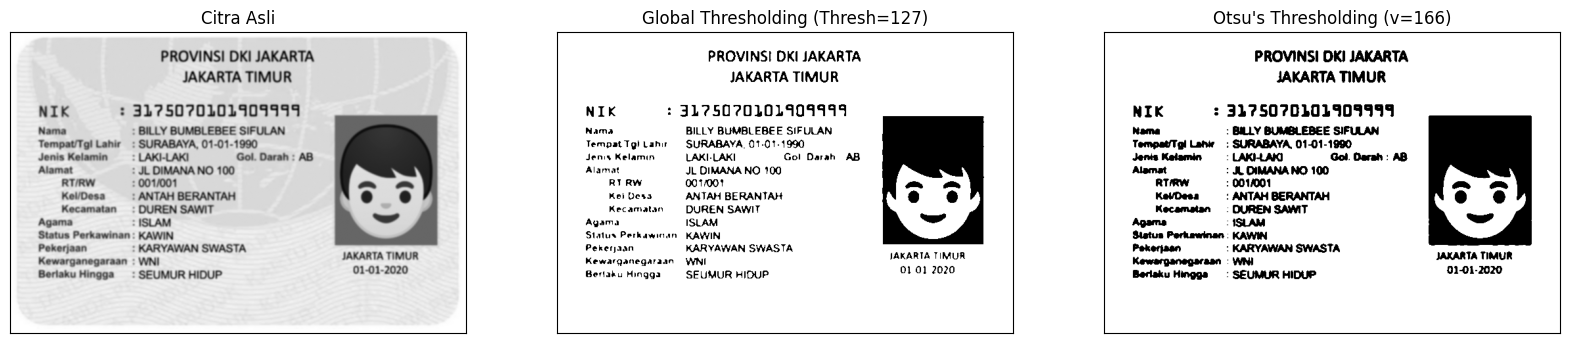

In [62]:
#ktp
filename = path + '/ktp_fulan.jpg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v=") + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh=' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i+1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

## 6. A. Lakukan Segmentasi Berbasis Region, B. Gunakan skimage.segmentation.flood().

In [42]:
# fungsi region growing
def region_growing(img, seed, T):
    h, w = img.shape
    mask = np.zeros((h, w), dtype=bool)
    sy, sx = seed
    mask[sy, sx] = True

    total = int(img[sy, sx])
    count = 1
    q = deque([seed])

    while q:
        y, x = q.popleft()
        for dy, dx in [(-1,0),(1,0),(0,-1),(0,1)]:
            ny, nx = y+dy, x+dx
            if 0 <= ny < h and 0 <= nx < w and not mask[ny, nx]:
                if abs(int(img[ny, nx]) - (total / count)) <= T:
                    mask[ny, nx] = True
                    total += int(img[ny, nx])
                    count += 1
                    q.append((ny, nx))
    return mask

Ukuran citra: (303, 384)
Seed Dalam koin: (baris=36, kolom=43) | intensitas: 159
Seed Latar: (baris=10, kolom=10) | intensitas: 127
Seed Tepi koin: (baris=84, kolom=100) | intensitas: 89


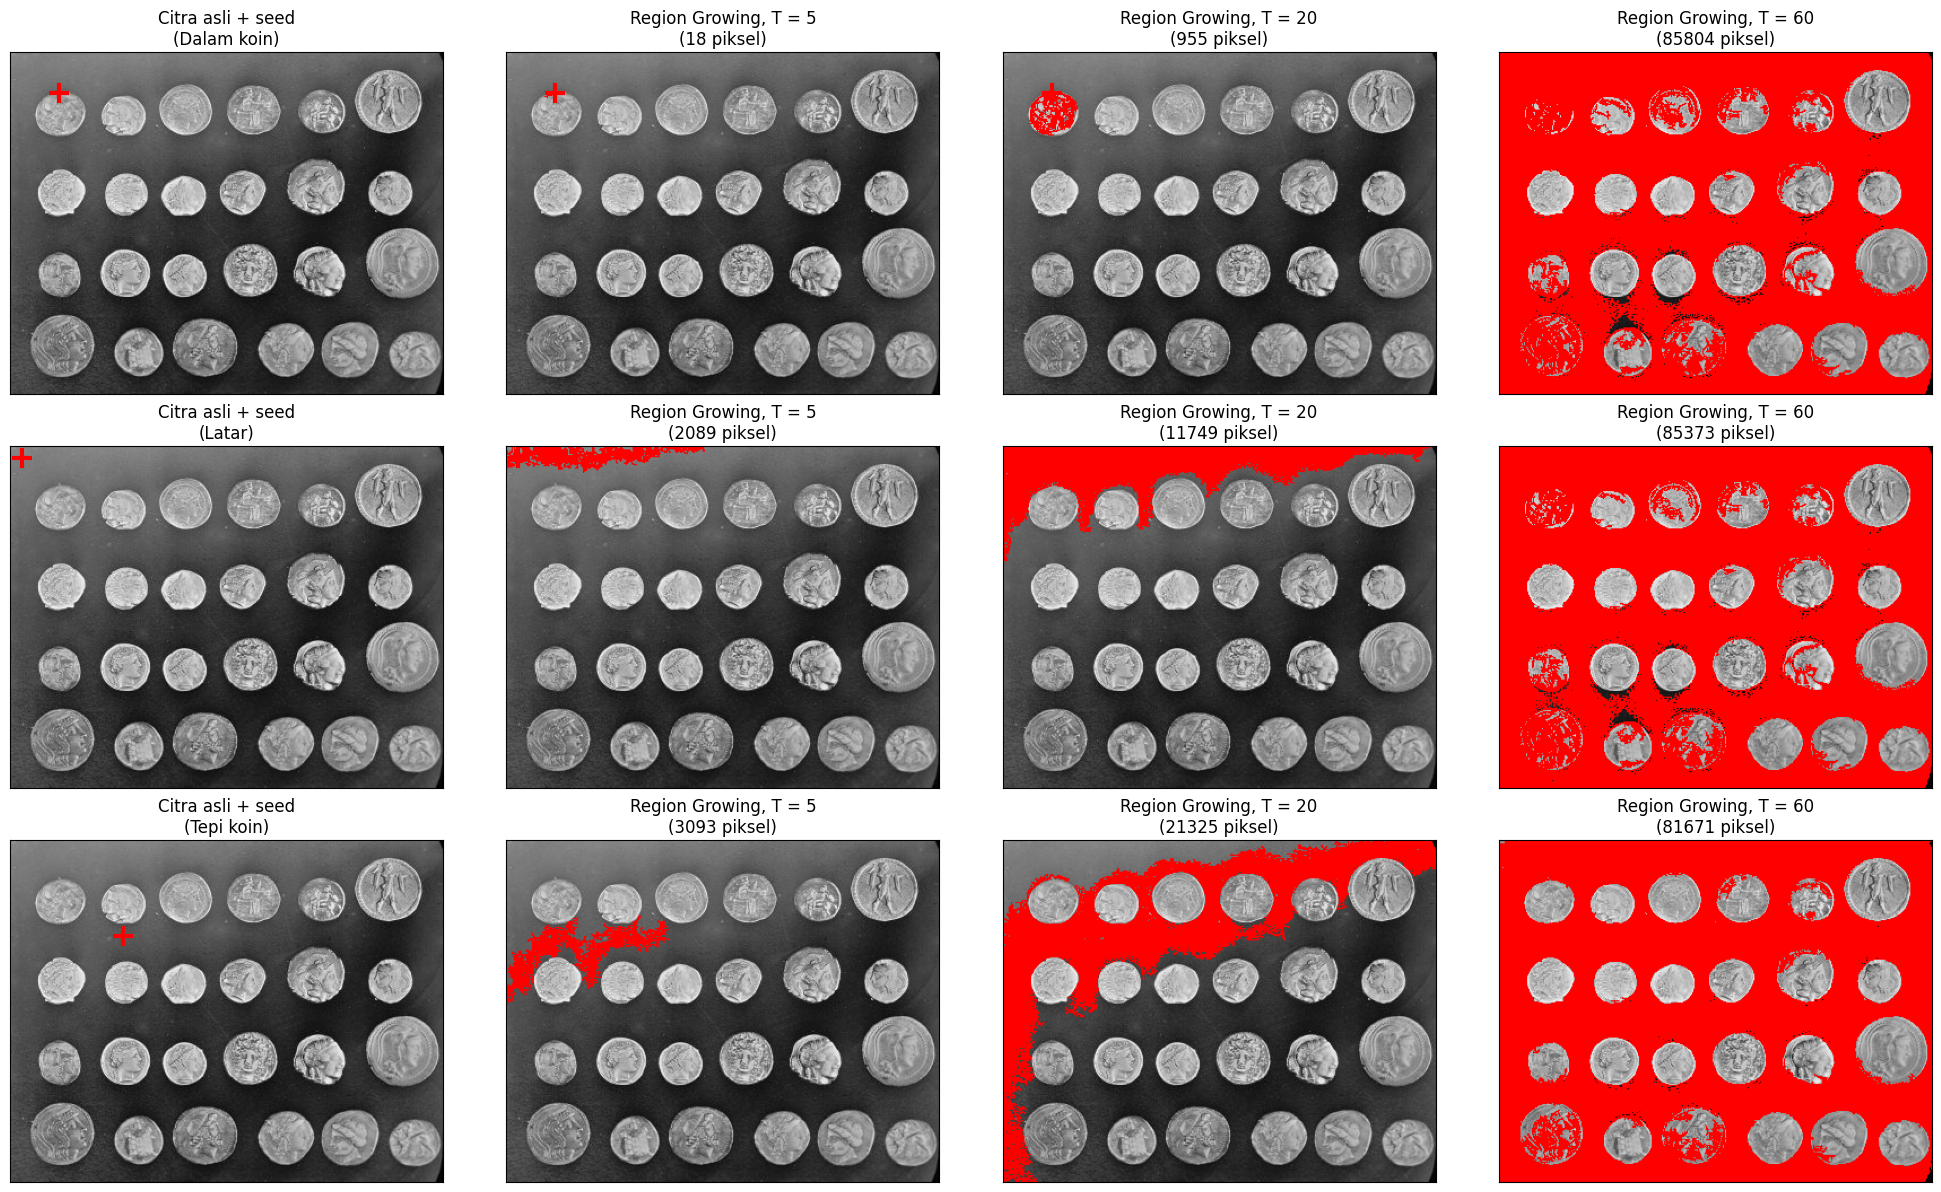

In [64]:
gray = data.coins()
print('Ukuran citra:', gray.shape)  # (303, 384)

# tentukan seed
seed_koin = (36, 43)
seed_latar = (10, 10)
seed_tepi = (84, 100)

seeds = [('Dalam koin', seed_koin),
         ('Latar', seed_latar),
         ('Tepi koin', seed_tepi)]

# output seed
for nama, s in seeds:
    intensitas = gray[s[0], s[1]]
    print(f'Seed {nama}: (baris={s[0]}, kolom={s[1]}) | intensitas: {intensitas}')

# output
nilai_T = [5, 20, 60]

plt.figure(figsize=(20, 12))
for i, (nama, seed) in enumerate(seeds):
    plt.subplot(3, 4, i * 4 + 1)
    plt.imshow(gray, cmap='gray')
    plt.plot(seed[1], seed[0], 'r+', markersize=15, markeredgewidth=3)
    plt.title(f'Citra asli + seed\n({nama})')
    plt.xticks([]), plt.yticks([])

    for j, T in enumerate(nilai_T):
        mask = region_growing(gray, seed, T)

        plt.subplot(3, 4, i * 4 + j + 2)
        display = np.stack([gray, gray, gray], axis=-1)
        display[mask] = [255, 0, 0]
        plt.imshow(display)
        plt.plot(seed[1], seed[0], 'r+', markersize=15, markeredgewidth=3)
        plt.title(f'Region Growing, T = {T}\n({mask.sum()} piksel)')
        plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

Seed (baris, kolom): (36, 43) | intensitas: 159
Toleransi 5: 21 piksel
Toleransi 20: 919 piksel
Toleransi 60: 15253 piksel


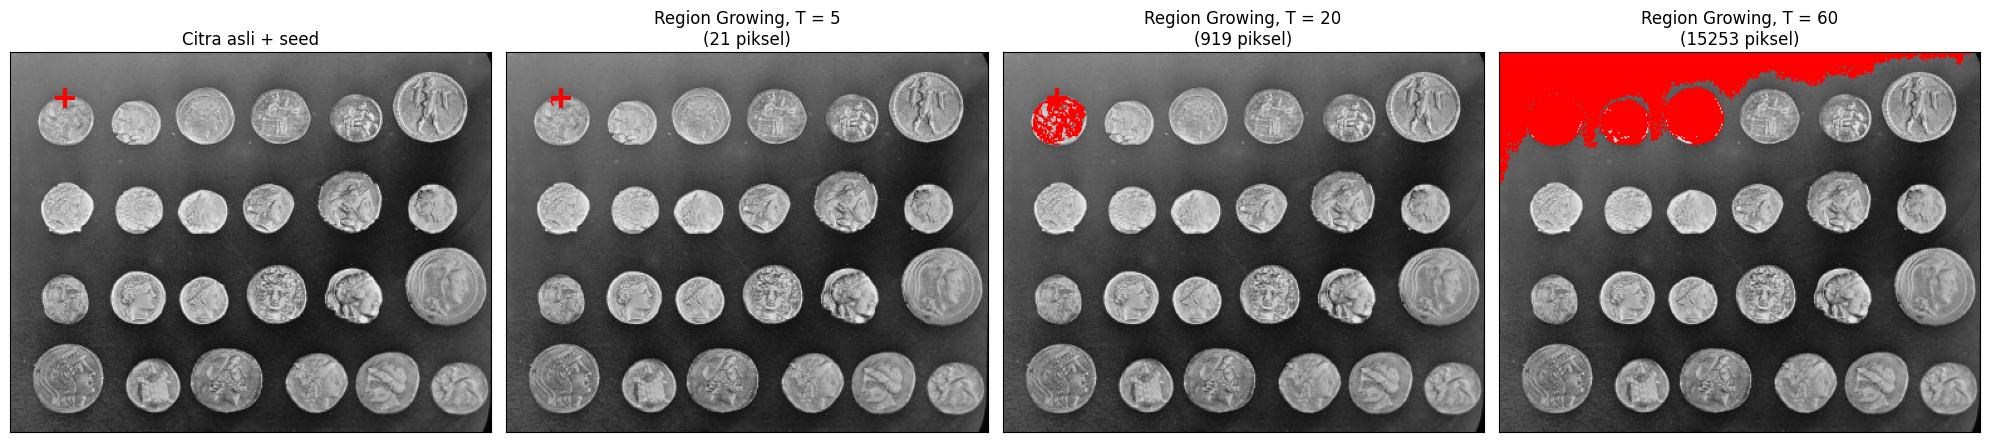

In [65]:
gray = data.coins()

# tentukan seed
seed = (36, 43)
intensitas = gray[seed[0], seed[1]]
print(f'Seed (baris, kolom): {seed} | intensitas: {intensitas}')

nilai_T = [5, 20, 60]

# piksel per toleransi
for T in nilai_T:
    mask = flood(gray, seed_point=seed, tolerance=T, connectivity=1)
    print(f'Toleransi {T}: {mask.sum()} piksel')

# output
plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.plot(seed[1], seed[0], 'r+', markersize=15, markeredgewidth=3)
plt.title('Citra asli + seed')
plt.xticks([]), plt.yticks([])

for j, T in enumerate(nilai_T):
    mask = flood(gray, seed_point=seed, tolerance=T, connectivity=1)

    plt.subplot(1, 4, j + 2)
    display = np.stack([gray, gray, gray], axis=-1)
    display[mask] = [255, 0, 0]
    plt.imshow(display)
    plt.plot(seed[1], seed[0], 'r+', markersize=15, markeredgewidth=3)
    plt.title(f'Region Growing, T = {T}\n({mask.sum()} piksel)')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

## 7. Lakukan segmentasi warna pada image ktp_fulan.jpg

In [66]:
from sklearn.cluster import KMeans

filename = path + '/ktp_fulan.jpg'
img = cv.imread(filename)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# k-means (k=8)
Z = img.reshape((-1, 3))
Z = np.float32(Z)

k = 8
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

# pilih yang biru saja
centers_hsv = cv.cvtColor(centers.reshape(1, -1, 3), cv.COLOR_RGB2HSV)[0]

kelompok_biru = np.where(
    (centers_hsv[:, 0] >= 85) &
    (centers_hsv[:, 0] <= 130) &
    (centers_hsv[:, 1] >= 25) &
    (centers_hsv[:, 2] >= 40)
)

label_map = labels.reshape(img.shape[:2])
mask_kmeans = np.isin(label_map, kelompok_biru)

hasil_kmeans = np.zeros_like(img)
hasil_kmeans[mask_kmeans] = img[mask_kmeans]

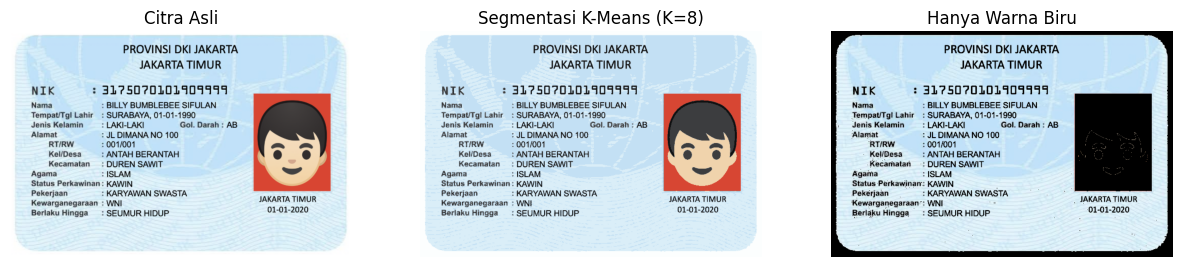

In [67]:
titles = ['Citra Asli', 'Segmentasi K-Means (K=8)', 'Hanya Warna Biru']
images = [img, segmented_img, hasil_kmeans]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis('off')
plt.show()

# D2. Tugas Kelompok

## Persiapan

In [70]:
import difflib
import cv2 as cv
import numpy as np
import pandas as pd
import pytesseract
from pytesseract import Output
import matplotlib.pyplot as plt

## Fungsi Pembantu

In [75]:
# normalisasi
def normalisasi(s):
    return ' '.join(s.lower().split())

# otsu manual
def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0: continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

# rata 1d untuk adaptive
def _rata_1d(img, kernel, axis):
    r = len(kernel) // 2
    if axis == 1:
        p = np.pad(img, ((0, 0), (r, r)), mode='reflect')
        out = np.zeros_like(img, dtype=np.float64)
        for i, w in enumerate(kernel):
            out += w * p[:, i:i + img.shape[1]]
    else:
        p = np.pad(img, ((r, r), (0, 0)), mode='reflect')
        out = np.zeros_like(img, dtype=np.float64)
        for i, w in enumerate(kernel):
            out += w * p[i:i + img.shape[0], :]
    return out

# adaptive manual
def adaptive_manual(gray, block, C, sigma=None):
    if sigma is None:
        kernel = np.ones(block) / block
    else:
        ax = np.arange(block) - block // 2
        kernel = np.exp(-(ax ** 2) / (2 * sigma ** 2))
        kernel /= kernel.sum()
    local = _rata_1d(_rata_1d(gray.astype(np.float64), kernel, 1), kernel, 0)
    T = local - C
    return np.where(gray > T, 255, 0).astype(np.uint8)

# siapkan citra
def siapkan_citra(path_ktp):
    img = cv.imread(path_ktp)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    blur = cv.GaussianBlur(gray, (5,5), 0)

    otsu_biner, _ = otsu(blur)
    th_adaptive = adaptive_manual(gray, 11, 2, sigma=2)

    return img, otsu_biner, th_adaptive

# kotak ocr
def kotak_ocr(img, conf_min=60):
    d = pytesseract.image_to_data(img, lang=LANG, config=f'--psm {PSM}', output_type=Output.DICT)
    n = len(d['text'])
    vis = img.copy() if len(img.shape) == 3 else cv.cvtColor(img, cv.COLOR_GRAY2BGR)
    confs = []
    for i in range(n):
        c = int(d['conf'][i])
        if c >= conf_min:
            confs.append(c)
            (x, y, w, h) = (d['left'][i], d['top'][i], d['width'][i], d['height'][i])
            cv.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
    return cv.cvtColor(vis, cv.COLOR_BGR2RGB), confs

# cocok
def cocok(item, teks):
    return normalisasi(item) in normalisasi(teks)

# baris terdekat
def baris_terdekat(item, teks, cutoff=0.55):
    target = normalisasi(item)
    baris = [l.strip() for l in teks.splitlines() if l.strip()]
    best, best_r = '-', 0.0
    for l in baris:
        if target in normalisasi(l):
            return l
        r = difflib.SequenceMatcher(None, target, normalisasi(l)).ratio()
        if r > best_r:
            best_r, best = r, l
    return best if best_r >= cutoff else '-'

# potong teks
def potong(teks, maks=24):
    teks = ' '.join(str(teks).split())
    return teks if len(teks) <= maks else teks[:maks - 1] + '~'

# tabel border
def tabel_border(df, judul=''):
    import builtins
    kolom = list(df.columns)
    isi = df.astype(str).values.tolist()
    lebar = [builtins.max([len(str(c))] + [len(str(r[j])) for r in isi]) for j, c in enumerate(kolom)]
    def garis(kiri, tengah, kanan):
        return kiri + tengah.join('-' * (w + 2) for w in lebar) + kanan
    def baris_t(nilai):
        return '| ' + '| '.join(str(v).ljust(w) for v, w in zip(nilai, lebar)) + '|'
    if judul: print(judul)
    print(garis('+', '+', '+'))
    print(baris_t(kolom))
    print(garis('+', '+', '+'))
    for r in isi: print(baris_t(r))
    print(garis('+', '+', '+'))

## Daftar Anggota &  Acuan

In [72]:
# ktp anggota
anggota = {
    'abdulghofuralmiqbadi': path + '/kel_ktp/ktp_abdulghofuralmiqbadi.jpeg',
    'muhammadfirmanaditiasmara': path + '/kel_ktp/ktp_muhammadfirmanaditiasmara.jpeg',
    'muhammadihsanrahmatullah': path + '/kel_ktp/ktp_muhammadihsanrahmatullah.jpeg',
    'salmanuranindhia': path + '/kel_ktp/ktp_salmanuranindhia.jpeg',
}

# ocr
LANG = 'ind'
PSM = 6
CONF_MIN = 60

# field acuan ktp
ACUAN = ['NAMA', 'TEMPAT/TGL', 'ALAMAT', 'RT/RW', 'KEL/DESA', 'KECAMATAN',
         'AGAMA', 'STATUS PERKAWINAN', 'PEKERJAAN', 'KEWARGANEGARAAN',
         'BERLAKU HINGGA']

## Proses Semua Anggota




Tabel perbandingan OCR - KTP abdulghofuralmiqbadi
+-----+-------------------+--------------------------+---------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli       | OCR Segmentasi Otsu| OCR Segmentasi Adaptive|
+-----+-------------------+--------------------------+---------------------+-------------------------+
| 1  | NAMA             | -                       | -                  | na an                  |
| 2  | TEMPAT/TGL       | -                       | -                  | -                      |
| 3  | ALAMAT           | -                       | -                  | -                      |
| 4  | RT/RW            | -                       | -                  | -                      |
| 5  | KEL/DESA         | -                       | -                  | -                      |
| 6  | KECAMATAN        | Kecamatan Em An :       | -                  | -                      |
| 7  | AGAMA            | -                       | -    

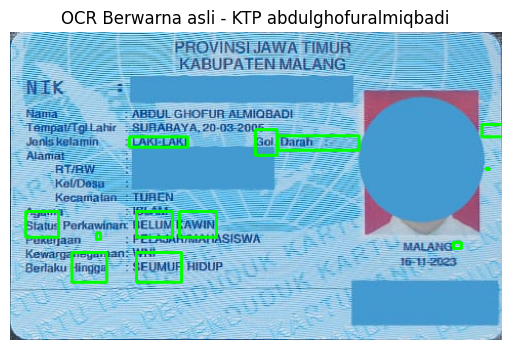


- Teks mentah OCR - KTP abdulghofuralmiqbadi (Berwarna asli) -
Sa KKBUPATENMALANG 0G
NIKo | EA
LKama  ABDULGHOFURALMIOBADI 3
Tampal/Tgitahir “SURABAYA,20-022005-————— —
Joniskelamin- - LAKELAKI Gol. Darah 1 —
LATAW — 2
er “AA
Kecamatan Em An :
Paman SA
- Status Perkawinan BELUM KAWIN — —— ed
Pekerjaan — —: PELAJAR/MAHASISWA oo” — —
Kewarganegaraan WNI —— 5 55 —
Berlaku Hingga — - SEUMUR HIDUP —— 7 MEM2O23


Tabel perbandingan OCR - KTP abdulghofuralmiqbadi
+-----+-------------------+--------------------------+---------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli       | OCR Segmentasi Otsu| OCR Segmentasi Adaptive|
+-----+-------------------+--------------------------+---------------------+-------------------------+
| 1  | NAMA             | -                       | -                  | na an                  |
| 2  | TEMPAT/TGL       | -                       | -                  | -                      |
| 3  | ALAMAT           | -           

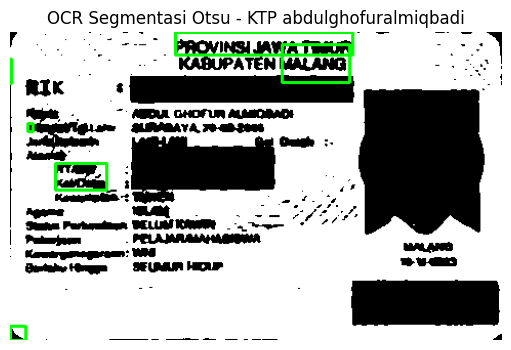


- Teks mentah OCR - KTP abdulghofuralmiqbadi (Segmentasi Otsu) -
. LI PROVINSIJAWATMUR “1
| KABUPATEN MALANG Hg
ae. MAAN 5
Sai T MEKAA GHOFUA MIOBADI
“ MABAYA. Pe-abPa0t
Ke-3 aa
A 3
ar aan
aman KAN LX end
Pera PELAJARAMHASNWA
Pe aan maa
“ Ban y


Tabel perbandingan OCR - KTP abdulghofuralmiqbadi
+-----+-------------------+--------------------------+---------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli       | OCR Segmentasi Otsu| OCR Segmentasi Adaptive|
+-----+-------------------+--------------------------+---------------------+-------------------------+
| 1  | NAMA             | -                       | -                  | na an                  |
| 2  | TEMPAT/TGL       | -                       | -                  | -                      |
| 3  | ALAMAT           | -                       | -                  | -                      |
| 4  | RT/RW            | -                       | -                  | -                      |
| 5  |

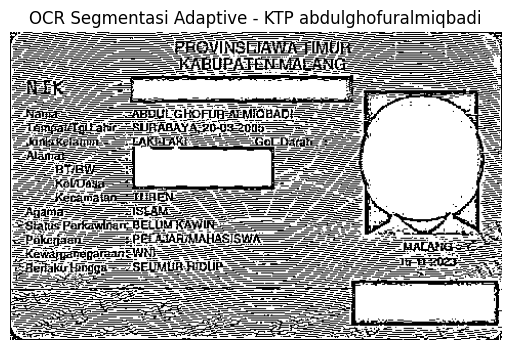


- Teks mentah OCR - KTP abdulghofuralmiqbadi (Segmentasi Adaptive) -
An —
Pa ae 5
amatlah SURAAAY SSos ani 2 5 pe
aenebum MAKE Go Darah 5 2
Pn ata — 5 AA 5
AN ea 4 Ez
na an


Tabel perbandingan OCR - KTP muhammadfirmanaditiasmara
+-----+-------------------+-------------------+--------------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli| OCR Segmentasi Otsu     | OCR Segmentasi Adaptive|
+-----+-------------------+-------------------+--------------------------+-------------------------+
| 1  | NAMA             | -                | Alamat                  | NATA —                 |
| 2  | TEMPAT/TGL       | -                | -                       | -                      |
| 3  | ALAMAT           | -                | Alamat                  | -                      |
| 4  | RT/RW            | -                | AT RW                   | -                      |
| 5  | KEL/DESA         | -                | re: Desa                | -               

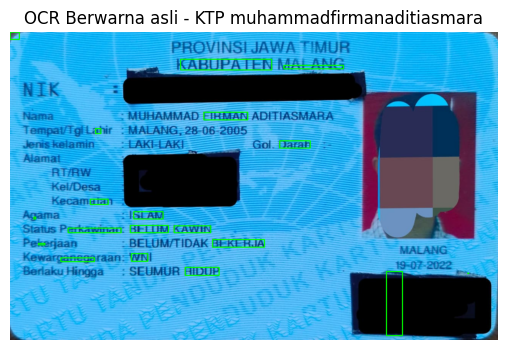


- Teks mentah OCR - KTP muhammadfirmanaditiasmara (Berwarna asli) -
£ DN
KABUPATEN MALANG
MUHAMMAD FIRMAN ADHFTFASMAR7
at MAFANG-28-06-2905
h AKA sol. Darah
ataf «
J SEAM
erkawinan BELUM KAWIN
ke BELUM/TIDAK BEKERJA
-. janega a WN -
. dingg SEHMER HIDUP | 7


Tabel perbandingan OCR - KTP muhammadfirmanaditiasmara
+-----+-------------------+-------------------+--------------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli| OCR Segmentasi Otsu     | OCR Segmentasi Adaptive|
+-----+-------------------+-------------------+--------------------------+-------------------------+
| 1  | NAMA             | -                | Alamat                  | NATA —                 |
| 2  | TEMPAT/TGL       | -                | -                       | -                      |
| 3  | ALAMAT           | -                | Alamat                  | -                      |
| 4  | RT/RW            | -                | AT RW                   | -                      |
| 

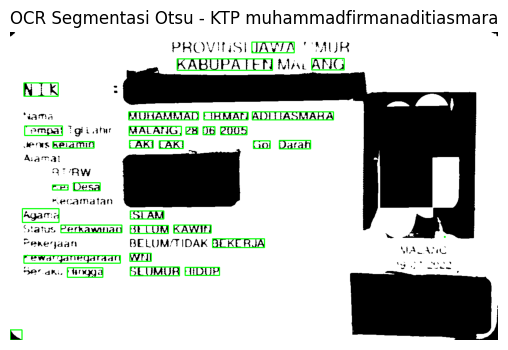


- Teks mentah OCR - KTP muhammadfirmanaditiasmara (Segmentasi Otsu) -
P 1
PROVIUSI JAWA "'MUR
KABUPATEN Mp4 ANG
NIK :
ama MUHAMMAD FIRMAN ADITIASMARA
Tempat 'giiahur MALANG, 28 06 2905
Jeras kelamin LAKI LAKI Gol Darah
Alamat
AT RW
re: Desa
secamatan
Agama ISLAM
Status Perkawnan BELUM KAWIN - ,
Pekegaan BELUM,/TIDAK BEKERJA MALANG
“ewaryanegaraan WII ai “ 1 an
Beam Hingga SEUMUR HIDUP Makau
“ 0)


Tabel perbandingan OCR - KTP muhammadfirmanaditiasmara
+-----+-------------------+-------------------+--------------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli| OCR Segmentasi Otsu     | OCR Segmentasi Adaptive|
+-----+-------------------+-------------------+--------------------------+-------------------------+
| 1  | NAMA             | -                | Alamat                  | NATA —                 |
| 2  | TEMPAT/TGL       | -                | -                       | -                      |
| 3  | ALAMAT           | -                | Alamat  

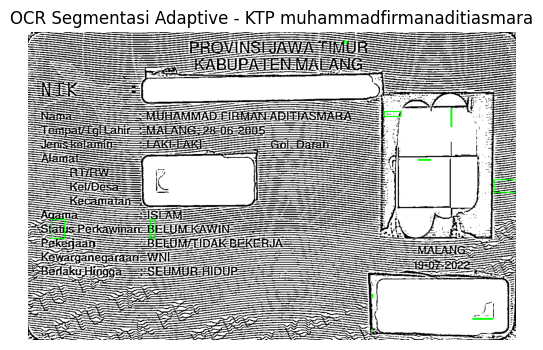


- Teks mentah OCR - KTP muhammadfirmanaditiasmara (Segmentasi Adaptive) -
AL AIKR NA PP
1 Aa Pa PA ae. t - —5—55——
AS  — — PRSINS Aa
PA PA PU Pee AA —————
Pe SAHU Pe NA AR PP
 —“..5.n E————
1 TA
- Sa
Nara VE HA AB PERAN EADFEFASMAREA Br Ka ——
3 Na ma Sa en Ae 37 | Na
Aa ——H— wi HF
Aina 7 2 ni — 1 : ——
we | LK »——.—.—.. ”
kemana Pr P
-— —— -
SS an Perma e B EU M KAIN —-——— PA Pan 0. —
— nan an Mean aa
Pa UANG
ee no 5
5 2
eraktr 1 PEP — TAS
TEE C1 :
3 |
TE KP we) AE
NATA —
CA PPPA 3 g
En Aa 3 AN ma,


Tabel perbandingan OCR - KTP muhammadihsanrahmatullah
+-----+-------------------+--------------------------+--------------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli       | OCR Segmentasi Otsu     | OCR Segmentasi Adaptive|
+-----+-------------------+--------------------------+--------------------------+-------------------------+
| 1  | NAMA             | Nama : MUHAMMAD IHSAN R~| -                       | -                      |
| 2  | TEMPAT/TGL 

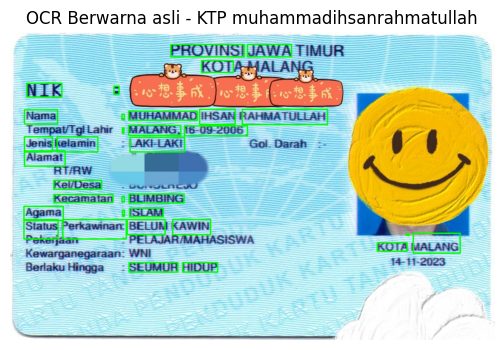


- Teks mentah OCR - KTP muhammadihsanrahmatullah (Berwarna asli) -
PROVINSI JAWA HMUR
KOT tA
NIK :
Nama : MUHAMMAD IHSAN RAHMATULLAH
Tempat'TgiLlahir : MALANG, 16-09-2006
Jenis kelamin 1 LAKI-LAKI Gol. Darah :-
Alamat 2
at,
Kel/Desa wi
Kecamatan : BLIMBING
Agama 2 ISLAM
Status Perkawinan BELUM KAWIN 2
Aa — ——— — — KOTA MALANG
Berlaku Hingga: SEUMUR HIDUP SA ——
an


Tabel perbandingan OCR - KTP muhammadihsanrahmatullah
+-----+-------------------+--------------------------+--------------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli       | OCR Segmentasi Otsu     | OCR Segmentasi Adaptive|
+-----+-------------------+--------------------------+--------------------------+-------------------------+
| 1  | NAMA             | Nama : MUHAMMAD IHSAN R~| -                       | -                      |
| 2  | TEMPAT/TGL       | -                       | -                       | -                      |
| 3  | ALAMAT           | Alamat 2                | 

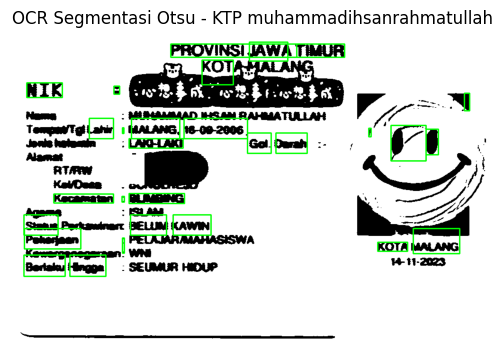


- Teks mentah OCR - KTP muhammadihsanrahmatullah (Segmentasi Otsu) -
PROVINSI JAWA TIMUR
sha KOT UV mnta YR
NIK 3 “al S1 INN ON - 8 |
Ma MANA po
Temput/Tgi Lahir : MALANG, 16-00-2006. / r
Jenehalamin ——: LAKI-LAKI Gol. Darah :-— ' 1
“—.. HD)
Kecamatan : BUMDING 2.
Status Perkawinan BELUM KAWIN Ps
Pekerjaan : PELAJARAMAHASISWA KOTA MALANG
Bertaku Hingga H SEUMUR HoUP Hina
Na 5.


Tabel perbandingan OCR - KTP muhammadihsanrahmatullah
+-----+-------------------+--------------------------+--------------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli       | OCR Segmentasi Otsu     | OCR Segmentasi Adaptive|
+-----+-------------------+--------------------------+--------------------------+-------------------------+
| 1  | NAMA             | Nama : MUHAMMAD IHSAN R~| -                       | -                      |
| 2  | TEMPAT/TGL       | -                       | -                       | -                      |
| 3  | ALAMAT           | Alamat 2    

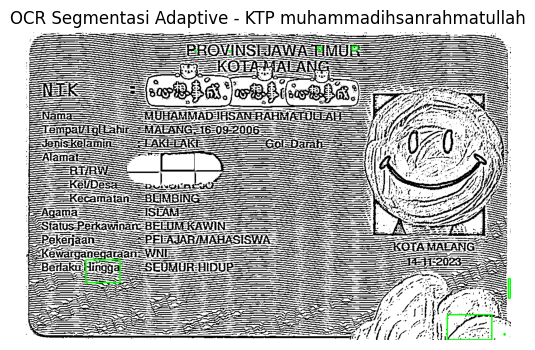


- Teks mentah OCR - KTP muhammadihsanrahmatullah (Segmentasi Adaptive) -
Pa Pr T AA 5 5
FA — SA 1 VINSIE Ae AA ——
AA ip KONTAN P5
Pe 5 BAN aa an
5 - an 5101 71 1 MA AMAN

nee AG ANTA
pa Bk V2 Ie
E-am : NN RL YANG,

an ane
FE Kewarganegaraan Ne
P-Beraki Hingga 2 SEUMUR AIDUI 2
PA AA
PES 3 CA aa an |
Pes aa Ah LN gamth
PA — AA —— ka SS er at ana AR
Ke Sm SI) fe AN YA |


Tabel perbandingan OCR - KTP salmanuranindhia
+-----+-------------------+--------------------------+--------------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli       | OCR Segmentasi Otsu     | OCR Segmentasi Adaptive|
+-----+-------------------+--------------------------+--------------------------+-------------------------+
| 1  | NAMA             | -                       | Nama. : SALMA NUR ANIND~| -                      |
| 2  | TEMPAT/TGL       | -                       | -                       | -                      |
| 3  | ALAMAT           | -                       | Alam

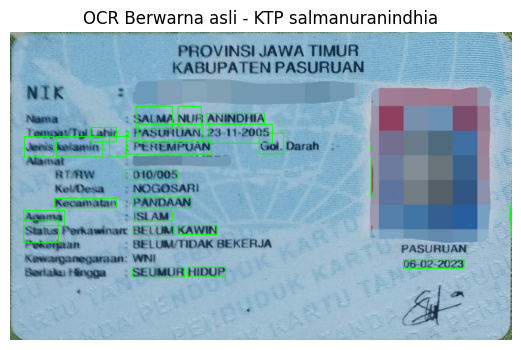


- Teks mentah OCR - KTP salmanuranindhia (Berwarna asli) -
PE en PP
“3 “EL KABUPATENPASURYAN
Nara 2 SALMA NUR ANINDHIA 3 PI 2
Tampan Tpi Lahir : PASURUAN, 23-11-2005 —— —....... | 5
Jenis kelamin — PEREMPUAN Gal. Darah — | .

RTRW: 010/005 mena | »

Kecamatan - PANDAAN a P5 | :
Agama 3 ISLAM : Ann gak |
Status Perkawinar BELUM KAWIN Na |
na si BELA POAK BEKERJA ! Hmmm —
Berlaku Hingga —: SEUMUR HIDUP 06-02-2023


Tabel perbandingan OCR - KTP salmanuranindhia
+-----+-------------------+--------------------------+--------------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli       | OCR Segmentasi Otsu     | OCR Segmentasi Adaptive|
+-----+-------------------+--------------------------+--------------------------+-------------------------+
| 1  | NAMA             | -                       | Nama. : SALMA NUR ANIND~| -                      |
| 2  | TEMPAT/TGL       | -                       | -                       | -                      |
| 3  | ALAM

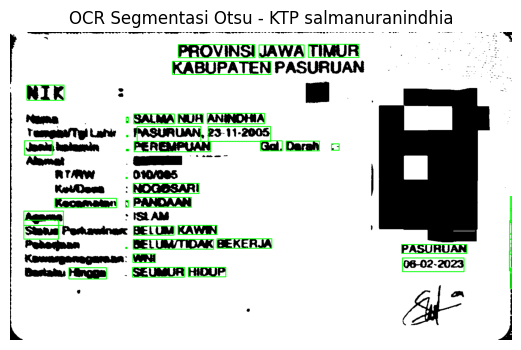


- Teks mentah OCR - KTP salmanuranindhia (Segmentasi Otsu) -
Temuan anna naa ana en an nn 5 ks ON
PROVINSI JAWA TIMUR 2. ai
KABUPATEN PASURUAN Mm
NIK z n "
Nama. : SALMA NUR ANINDHIA
Temgua/Tgi Lah . PASURUAN, 23-11-2005
Janda alamin . PEREMPUAN Gol. Darah :-
Alamat .——.—..
NT AM : 0W/085
Kelam —: NOGOSARI
Kecamatan : PANDAAN |
Agama "ISLAM |
Sintus Perhawinax BELUM KAWIN ' |
Peharjaan . BELUM/TIDAK BEKERJA PASURUAN |
Kamusgangaaan: WNI 06-02-2023 |
Bastatu Hingga —. SEUMUR HIDUP |
0 EN


Tabel perbandingan OCR - KTP salmanuranindhia
+-----+-------------------+--------------------------+--------------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli       | OCR Segmentasi Otsu     | OCR Segmentasi Adaptive|
+-----+-------------------+--------------------------+--------------------------+-------------------------+
| 1  | NAMA             | -                       | Nama. : SALMA NUR ANIND~| -                      |
| 2  | TEMPAT/TGL       | -          

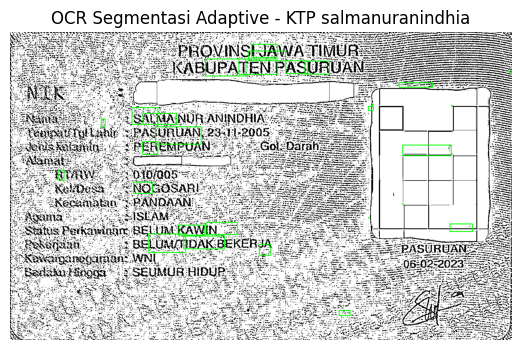


- Teks mentah OCR - KTP salmanuranindhia (Segmentasi Adaptive) -
daan
NE
Ma TEsIaa PA San
- aa LA Tea Su Ta Tina Da PN ab e ag
BEE Ps ata PA A3 na Bea EN
Pa 1 TEEAUN Ma Ii FePRt IE Aa ai Ai
Lp 2 Pe aa ses Kg Ta aa |. JA Aa Ten nan
Banana NE NE er Sada UPAT ENP A TIMUR, ——— FE
- Na Ba antar teih TENI Kuta Mur
“3 NO Batan 1 AS Sae EA z nee PA Si
“ a an MN en UR Nee SEA SA An
8 Sa Ti Tan ae Pan gas aa Rana MN Ng: AL AN 5 Aan
3 " Kenal Sae i ag Ta BALI Kana Dan Han sURUAN TT ———
Pena 2 Talkahi « F ALMA: an Aa —— - Ae ——
PE ANA Ea SIR PN na #NL PARI AAN? pa ——————
nan ba SPASURU: IANINDHIA aa. 2 aa Ta ——
ag Hai DAN Uki BEP URUAN D3 DHI Nee ain — “——
5 nan KE Na EA Haa ea 23x TH MALE ne 1 SS 2
an Ta Pa (EMPU nata Tm ge 5 | 3.
. Tn TEE t Du Kan Pe mnaang una £ ANE: OA Tenan 3g Dea PR PA
HA retoui ngan ———. ajaa P0 | (—
SN He NG 3 Nu BA Tah Mena AD PENS RTA Br 2 p—
TU thea 5 2 Otojaon 2 TT Je: Haa Ea
1 2 EK 2 - ng Pa Na Sa) Ba Ha ne TT Fs
21 “Agania " ti atul BANI SAR F3 Ba jan
ea aan SU SPAN

In [76]:
ringkasan = []

# iterasi menggunakan dictionary anggota
for nama, path_ktp in anggota.items():
    img_asli, img_otsu, img_adapt = siapkan_citra(path_ktp)
    teks_asli = pytesseract.image_to_string(img_asli, lang=LANG, config=f'--psm {PSM}')
    teks_otsu = pytesseract.image_to_string(img_otsu, lang=LANG, config=f'--psm {PSM}')
    teks_adapt = pytesseract.image_to_string(img_adapt, lang=LANG, config=f'--psm {PSM}')

    for metode, teks, citra in [('Berwarna asli', teks_asli, img_asli),
                                ('Segmentasi Otsu', teks_otsu, img_otsu),
                                ('Segmentasi Adaptive', teks_adapt, img_adapt)]:
        tepat = 0
        for item in ACUAN:
            if cocok(item, teks):
                tepat += 1
        persentase = round(100 * tepat / len(ACUAN), 1)

        _, confs = kotak_ocr(citra)
        rata_conf = round(np.mean(confs), 1) if confs else 0.0

        ringkasan.append({
            'Anggota': nama,
            'Citra masukan OCR': metode,
            'Item terbaca tepat': tepat,
            'Kecocokan (%)': persentase,
            'Rata-rata confidence': rata_conf,
        })

        # tabel perbandingan
        print(f"\nTabel perbandingan OCR - KTP {nama}")
        df = pd.DataFrame([[i, item, potong(baris_terdekat(item, teks_asli)),
                            potong(baris_terdekat(item, teks_otsu)),
                            potong(baris_terdekat(item, teks_adapt))]
                           for i, item in enumerate(ACUAN, 1)],
                          columns=['No.', 'Teks sebenarnya', 'OCR Berwarna asli',
                                   'OCR Segmentasi Otsu', 'OCR Segmentasi Adaptive'])
        tabel_border(df)

        # kotak OCR
        vis, _ = kotak_ocr(citra, CONF_MIN)
        plt.figure(figsize=(15, 4))
        plt.imshow(vis)
        plt.title(f'OCR {metode} - KTP {nama}')
        plt.axis('off')
        plt.show()

        print(f"\n- Teks mentah OCR - KTP {nama} ({metode}) -")
        print(teks)

## RINGKASAN

In [77]:
df = pd.DataFrame(ringkasan)
METODE = ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive']

def pivot_ringkasan(fmt):
    baris = []
    for nama in df['Anggota'].unique():
        row = {'Anggota': nama}
        for m in METODE:
            r = df[(df['Anggota'] == nama) & (df['Citra masukan OCR'] == m)].iloc[0]
            row[m] = fmt(r)
        baris.append(row)
    return pd.DataFrame(baris)

tabel_border(pivot_ringkasan(lambda r: f"{r['Item terbaca tepat']} ({r['Kecocokan (%)']}%)"),
             'Kecocokan tiap metode - item tepat / persen')
tabel_border(pivot_ringkasan(lambda r: f"{r['Rata-rata confidence']}"),
             'Rata-rata confidence tiap metode')

Kecocokan tiap metode - item tepat / persen
+---------------------------+---------------+-----------------+---------------------+
| Anggota                  | Berwarna asli| Segmentasi Otsu| Segmentasi Adaptive|
+---------------------------+---------------+-----------------+---------------------+
| abdulghofuralmiqbadi     | 5 (45.5%)    | 0 (0.0%)       | 0 (0.0%)           |
| muhammadfirmanaditiasmara| 0 (0.0%)     | 2 (18.2%)      | 0 (0.0%)           |
| muhammadihsanrahmatullah | 7 (63.6%)    | 3 (27.3%)      | 1 (9.1%)           |
| salmanuranindhia         | 3 (27.3%)    | 4 (36.4%)      | 0 (0.0%)           |
+---------------------------+---------------+-----------------+---------------------+
Rata-rata confidence tiap metode
+---------------------------+---------------+-----------------+---------------------+
| Anggota                  | Berwarna asli| Segmentasi Otsu| Segmentasi Adaptive|
+---------------------------+---------------+-----------------+---------------------+
|

## Tabel Ringkasan Kelompok

In [40]:
print('\n' + '='*70)
print('RINGKASAN KELOMPOK (4 ANGGOTA)')
print('='*70)

baris_total = []
for nama in anggota.keys():
    for tipe in ['Berwarna', 'Otsu', 'Adaptive']:
        # Hitung ulang kecocokan
        tepat = 0
        for item in acuan:
            terbaca = cari_item(hasil_semua[nama][tipe]['teks'], item)
            if normalisasi(terbaca) == normalisasi(item):
                tepat += 1
        baris_total.append([
            nama,
            tipe,
            tepat,
            f'{tepat / len(acuan) * 100:.1f}%',
            f"{hasil_semua[nama][tipe]['conf']:.2f}"
        ])

df_total = pd.DataFrame(
    baris_total,
    columns=['Anggota', 'Metode', 'Item Tepat (dari 10)', 'Kecocokan (%)', 'Rata-rata Confidence']
)
display(df_total)


RINGKASAN KELOMPOK (4 ANGGOTA)


,Anggota,Metode,Item Tepat (dari 10),Kecocokan (%),Rata-rata Confidence
0,abdulghofuralmiqbadi,Berwarna,5,50.0%,82.12
1,abdulghofuralmiqbadi,Otsu,0,0.0%,83.20
2,abdulghofuralmiqbadi,Adaptive,0,0.0%,75.50
3,muhammadfirmanaditiasmara,Berwarna,0,0.0%,84.12
4,muhammadfirmanaditiasmara,Otsu,5,50.0%,85.94
5,muhammadfirmanaditiasmara,Adaptive,2,20.0%,86.07
6,muhammadihsanrahmatullah,Berwarna,8,80.0%,86.65
7,muhammadihsanrahmatullah,Otsu,5,50.0%,87.65
8,muhammadihsanrahmatullah,Adaptive,3,30.0%,81.95
9,salmanuranindhia,Berwarna,4,40.0%,83.00


## Jawaban Pertanyaan Analisis

### Pertanyaan Analisis

Berdasarkan tabel ringkasan di atas (4 anggota x 3 metode, 11 item acuan):

1. Citra masukan mana yang menghasilkan pembacaan paling tepat?

Secara rata-rata kelompok, citra hasil Segmentasi Adaptive paling tepat:

Metode | Total item tepat | Rata-rata kecocokan
---|---|---
Berwarna asli | 11 / 44 | 25,0%
Segmentasi Otsu | 12 / 44 | 27,3%
Segmentasi Adaptive | 16 / 44 | 36,4%

Namun pembacaan individu terbaik justru Segmentasi Otsu pada KTP muhammadfirmanaditiasmara (6/11 = 54,5%). Jadi tidak ada satu metode yang menang di semua KTP — Adaptive unggul secara rata-rata, tetapi tiap anggota punya metode terbaiknya sendiri.

2. Contoh kesalahan pembacaan (minimal dua).

- Label ber-slash hilang: RT/RW, TEMPAT/TGL, dan KEL/DESA tidak pernah terbaca oleh metode apa pun. OCR menghapus garis miring, mis. pada KTP muhammadfirmanaditiasmara RT/RW terbaca RTARW, KEL/DESA terbaca Kei/Desa.
- Huruf tertukar / kata kacau pada citra berwarna: pada KTP muhammadfirmanaditiasmara (berwarna asli) NAMA terbaca acak (h AKELAP) dan AGAMA menjadi J SLEAM; pada KTP salmanuranindhia TEMPAT/TGL terbaca TempayTyiLahir dan BERLAKU HINGGA terbaca Baraku Mingga.
- Goresan putus pada Otsu: ALAMAT pada KTP muhammadfirmanaditiasmara terbaca Aiamai (huruf l/m pecah).

3. Apakah segmentasi selalu meningkatkan ketepatan OCR?

Tidak. Hasilnya bergantung citra:

- Membantu: KTP muhammadfirmanaditiasmara — berwarna 0,0% menjadi Otsu 54,5%. Ini karena citra berwarna muhammadfirmanaditiasmara (latar biru + foto disensor merah + miring) paling sulit dibaca Tesseract, dan thresholding berhasil membersihkan latar.
- Merugikan: KTP abdulghofuralmiqbadi — berwarna 45,5% turun ke Otsu 27,3%; KTP muhammadihsanrahmatullah — berwarna 45,5% turun ke Otsu 18,2%. Binarisasi menghapus gradasi abu-abu huruf dan membuat latar berpola guilloche ikut menjadi noise.

Kesimpulan: segmentasi membantu saat citra asli sulit (kontras/warna mengganggu), tetapi bisa merugikan saat citra asli sudah cukup jelas.

4. Pengaruh warna atau pola latar belakang.

Latar KTP biru dengan pola guilloche (garis halus melengkung) berpengaruh dua arah:
- Pada citra berwarna, Tesseract kesulitan membaca langsung citra 3-kanal (KTP muhammadfirmanaditiasmara 0%), terutama bila ada foto/sensor berwarna dan kemiringan.
- Setelah thresholding, pola guilloche bisa ikut ter-biner menjadi bercak noise (terlihat pada KTP abdulghofuralmiqbadi), sehingga huruf terpecah.
- Teks hitam di atas latar biru muda sebenarnya kontrasnya cukup, sehingga pada KTP yang bersih (abdulghofuralmiqbadi / muhammadihsanrahmatullah) citra berwarna sudah terbaca baik tanpa segmentasi.

5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?

Tidak.

Metode | Rata-rata confidence | Rata-rata kecocokan
---|---|---
Berwarna asli | 52,6 (tertinggi) | 25,0% (terendah)
Segmentasi Otsu | 50,3 | 27,3%
Segmentasi Adaptive | 37,2 (terendah) | 36,4% (tertinggi)

Confidence hanya mengukur keyakinan Tesseract pada tiap kata, bukan kebenarannya. Pada citra berwarna, Tesseract yakin tinggi walau banyak kata yang salah; pada citra Adaptive, confidence lebih rendah tetapi lebih banyak item yang benar-benar cocok. Jadi confidence tinggi tidak menjamin akurasi tinggi dan tetap harus dibandingkan dengan teks acuan.